# 01 — Exploração dos dados (Tema 7)
Objetivo: perceber os dados antes de modelar. Cada célula responde a uma pergunta que vamos usar no relatório.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.dados import carregar_leituras, SENSORES

df = carregar_leituras()
print(df.shape)
df.head()

(4800, 18)


,id_leitura,id_maquina,tipo_qualidade,timestamp,ciclo,temp_ar_K,temp_processo_K,velocidade_rpm,binario_Nm,desgaste_ferramenta_min,vibracao_mm_s,pressao_bar,corrente_A,horas_desde_manutencao,falha,tipo_falha,falha_nas_proximas_24h,leitura_anomala_sensor
0,L00001,MQ01,M,2026-09-01 00:00:00,0,297.33,307.63,1406.0,49.2,50.0,2.13,5.99,27.00,100,0,OK,0,False
1,L00002,MQ01,M,2026-09-01 01:00:00,1,297.39,305.82,1720.0,31.9,52.0,1.95,6.00,24.13,101,0,OK,0,False
2,L00003,MQ01,M,2026-09-01 02:00:00,2,297.43,308.42,1727.0,41.4,55.0,2.07,6.05,27.24,102,0,OK,0,False
3,L00004,MQ01,M,2026-09-01 03:00:00,3,297.49,NaN,1365.0,54.7,60.0,2.66,6.10,27.91,103,0,OK,0,False
4,L00005,MQ01,M,2026-09-01 04:00:00,4,297.57,308.14,1669.0,35.7,63.0,1.96,6.04,23.46,104,0,OK,0,False


## 1. Visão geral: máquinas, ciclos e período

In [2]:
print('Máquinas:', df.id_maquina.nunique(), '| ciclos por máquina:', df.groupby('id_maquina').size().unique())
print('Período:', df.timestamp.min(), '->', df.timestamp.max())
df.describe().T.round(2)

Máquinas: 12 | ciclos por máquina: [400]
Período: 2026-09-01 00:00:00 -> 2026-09-17 15:00:00


,count,mean,min,25%,50%,75%,max,std
timestamp,4800,2026-09-09 07:30:00,2026-09-01 00:00:00,2026-09-05 03:45:00,2026-09-09 07:30:00,2026-09-13 11:15:00,2026-09-17 15:00:00,NaN
ciclo,4800.0,199.5,0.0,99.75,199.5,299.25,399.0,115.481723
temp_ar_K,4800.0,297.979685,296.38,297.8,297.98,298.16,299.32,0.242385
temp_processo_K,4752.0,308.00214,304.48,307.38,307.97,308.57,320.21,1.040353
velocidade_rpm,4800.0,1530.125,1126.0,1446.0,1533.0,1615.0,1980.0,123.490982
binario_Nm,4800.0,40.454937,9.9,35.0,40.6,46.2,66.2,8.223659
desgaste_ferramenta_min,4800.0,112.557708,2.0,60.0,111.0,165.0,240.0,61.784679
vibracao_mm_s,4752.0,2.759186,0.8,2.23,2.59,3.04,12.39,0.953302
pressao_bar,4752.0,5.807731,5.01,5.7,5.82,5.93,6.3,0.177527
corrente_A,4800.0,24.860898,14.63,23.27,24.91,26.51,34.04,2.377263


## 2. Desequilíbrio dos alvos
**Porque importa:** só ~3% das leituras são falhas, por isso *accuracy* engana (prever sempre 'sem falha' dá ~97%). Vamos usar precisão, recall, F1 e PR-AUC.

falha                  : 0.0292
falha_nas_proximas_24h : 0.5385


tipo_falha
TWF    63
PWF    24
BRG    22
OSF    17
HDF    10
RNF     4
Name: count, dtype: int64

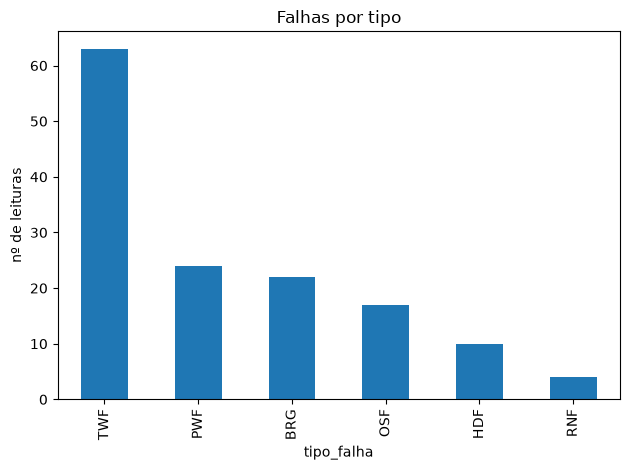

In [3]:
print('falha                  :', df.falha.mean().round(4))
print('falha_nas_proximas_24h :', df.falha_nas_proximas_24h.mean().round(4))
ordem = df[df.falha == 1].tipo_falha.value_counts()
display(ordem)
ordem.plot.bar(title='Falhas por tipo'); plt.ylabel('nº de leituras'); plt.tight_layout()
plt.savefig('../figuras/falhas_por_tipo.png', dpi=150); plt.show()

## 3. Valores em falta e picos de sensor
O LEIA-ME diz que ~1% dos valores faltam em 3 sensores e que há picos que **não** são falhas (`leitura_anomala_sensor`, só para análise).

In [4]:
print(df[SENSORES].isna().sum()[lambda s: s > 0])
print('Picos de sensor:', df.leitura_anomala_sensor.sum())
print('Picos que coincidem com falha:', ((df.leitura_anomala_sensor) & (df.falha == 1)).sum())

temp_processo_K    48
vibracao_mm_s      48
pressao_bar        48
dtype: int64
Picos de sensor: 49
Picos que coincidem com falha: 0


## 4. Séries temporais de uma máquina com falha de rolamento (BRG)
O desafio 1 do LEIA-ME: ver como a vibração sobe e a pressão desce **antes** da falha.

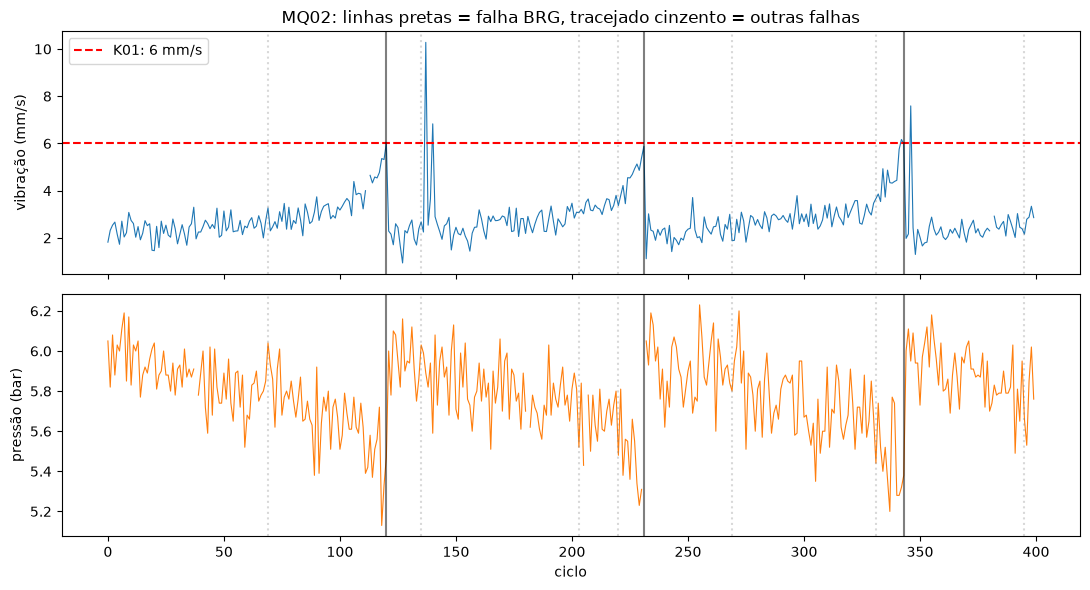

In [5]:
maq = df[df.tipo_falha == 'BRG'].id_maquina.value_counts().index[0]
d = df[df.id_maquina == maq]
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(d.ciclo, d.vibracao_mm_s, lw=.8); ax[0].axhline(6, ls='--', c='r', label='K01: 6 mm/s'); ax[0].set_ylabel('vibração (mm/s)'); ax[0].legend()
ax[1].plot(d.ciclo, d.pressao_bar, lw=.8, c='C1'); ax[1].set_ylabel('pressão (bar)'); ax[1].set_xlabel('ciclo')
for a in ax:
    for c in d[d.tipo_falha == 'BRG'].ciclo: a.axvline(c, c='k', alpha=.5)
    for c in d[(d.falha == 1) & (d.tipo_falha != 'BRG')].ciclo: a.axvline(c, c='gray', alpha=.3, ls=':')
ax[0].set_title(f'{maq}: linhas pretas = falha BRG, tracejado cinzento = outras falhas')
plt.tight_layout(); plt.savefig('../figuras/serie_BRG.png', dpi=150); plt.show()

## 5. Vibração e pressão: normal vs. antes de falha
Se as distribuições se separam, estas variáveis serão boas *features*.

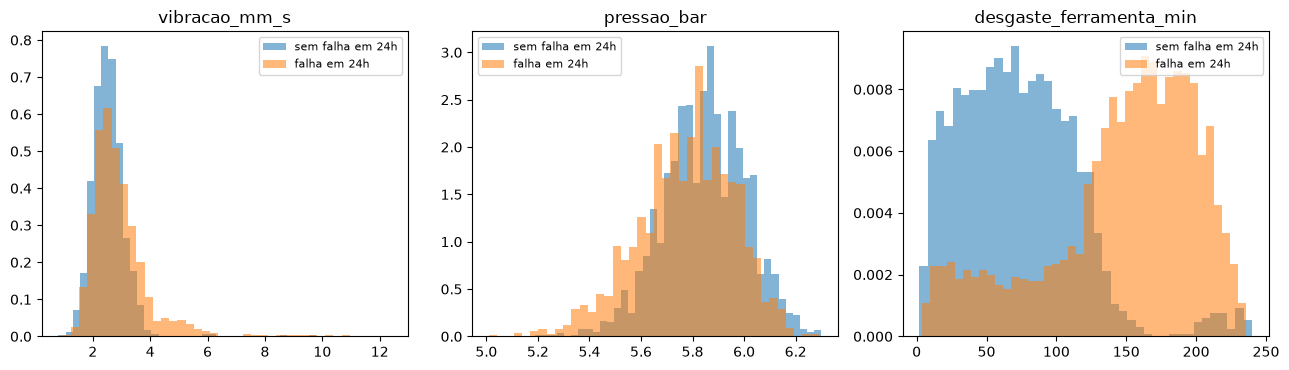

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, col in zip(ax, ['vibracao_mm_s', 'pressao_bar', 'desgaste_ferramenta_min']):
    for v, nome in [(0, 'sem falha em 24h'), (1, 'falha em 24h')]:
        a.hist(df[df.falha_nas_proximas_24h == v][col].dropna(), bins=40, alpha=.55, density=True, label=nome)
    a.set_title(col); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig('../figuras/distribuicoes_24h.png', dpi=150); plt.show()

## 6. Cuidado com a fuga de informação
`falha_nas_proximas_24h` é 'verdadeiro' em ~54% das leituras, e `desgaste_ferramenta_min` e `horas_desde_manutencao` são contadores que crescem com o tempo. Vamos ver como se comportam por máquina.

In [7]:
print(df.groupby('id_maquina').falha.sum().to_dict())
print('horas_desde_manutencao: max =', df.horas_desde_manutencao.max(), '-> a regra K07 (>240) dispara?', (df.horas_desde_manutencao > 240).sum(), 'vezes')
print(pd.crosstab(df.falha, df.falha_nas_proximas_24h))

{'MQ01': 15, 'MQ02': 10, 'MQ03': 11, 'MQ04': 10, 'MQ05': 13, 'MQ06': 12, 'MQ07': 15, 'MQ08': 11, 'MQ09': 8, 'MQ10': 10, 'MQ11': 10, 'MQ12': 15}
horas_desde_manutencao: max = 150 -> a regra K07 (>240) dispara? 0 vezes
falha_nas_proximas_24h     0     1
falha                             
0                       2129  2531
1                         86    54


## Conclusões do Passo 1

São 4800 leituras horárias de 12 máquinas com 400 ciclos cada, entre 1 e 17 de setembro de 2026. Apenas 140 leituras correspondem a falhas (2,9%), o que torna o problema bastante desequilibrado. Por isso, a accuracy não será utilizada como principal métrica de avaliação, sendo mais melhor a precisão, o recall, o F1-score e a PR-AUC.

Os dois alvos apresentam características diferentes, enquanto a falha é um evento raro (2,9%), falha_nas_proximas_24h é positivo em 53,9% das leituras, sendo um problema mais equilibrado e focado na capacidade de antecipação.

Quanto aos tipos de falha, a mais frequente é a TWF (63 casos), seguida de PWF (24 casos), BRG (22 casos), OSF (17 casos), HDF (10 casos) e RNF (4 casos). As falhas RNF são aleatórias , por isso são dificilmente previsíveis.

Em termos de qualidade dos dados, cerca de 1% dos valores estão em falta nos sensores de temperatura de processo, vibração e pressão (48 valores em cada). Foram também detetados 49 picos anómalos nos sensores que não correspondem a falhas reais, que podem gerar falsos alarmes.

Nas falhas BRG, observa-se um padrão claro, a vibração aumenta e a pressão diminui gradualmente durante cerca de 100 ciclos antes da falha, e regressa depois aos valores normais. Este comportamento justifica a utilização de características temporais, como tendências e médias móveis.

Por fim, verificou-se que a regra K07 nunca é ativada, uma vez que a variável horas_desde_manutencao não ultrapassa as 150 horas, ficando sempre abaixo do limite de 240 horas. Assim, o tratamento dos valores em falta, a divisão dos dados por máquina para evitar fuga de informação e a comparação entre abordagens baseadas em regras, machine learning e modelos híbridos serão aspetos fundamentais da modelação.